# Constrained Lifecycle Carbon Optimization & Pareto Frontier Analysis
**Project**: Modeling Earth Systems and Sustainability (MESS)  
**Deliverable**: Step 4 Execution Notebook for Concrete Carbon–Strength Optimization  
**Canonical Data Source**: [carbonation_master.csv](carbonation_master.csv)  

This notebook executes:
1. **Model Calibration & Discrepancy Reconciliation** (Strength LOO-RMSE = 4.38 MPa; Fickian & Power-law kinetics).
2. **Discrete Mix Screening** (Evaluating all 45 physical mixes under Sheltered vs. Unsheltered exposure with heuristic 4.4 MPa screening buffer).
3. **Continuous Constrained Optimization** (Multi-start SLSQP over empirical  \ge 220	ext{ kg/m}^3$ and code-informed  \ge 280	ext{ kg/m}^3$ envelopes).
4. **Authoritative Pareto Frontiers** ({\mathrm{net}}$ vs. {\mathrm{target}}$ across M30, M35, M40).
5. **Multi-Dimensional Sensitivity Sweeps** (Microclimate, SCM Allocation, Kinetics, Uptake Bounding, Compaction Air, Binder Bounds).

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.optimize import minimize
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 10, 'axes.labelsize': 11, 'axes.titlesize': 12,
    'figure.dpi': 120, 'lines.linewidth': 1.8, 'axes.spines.top': False, 'axes.spines.right': False
})

df_master = pd.read_csv('carbonation_master.csv')
print('Loaded master dataset:', df_master.shape, df_master['mix_id'].nunique(), 'unique mixes.')


Loaded master dataset: (353, 48) 45 unique mixes.


In [2]:
mix_cols = [
    'mix_id', 'notation', 'wb_ratio', 'binder_content_kg_m3', 'sand_kg_m3', 'gravel_kg_m3',
    'air_content_pct', 'fc_28d_mpa', 'curing_days_USED', 'curing_time_days', 'scm1_type', 'scm1_pct',
    'scm2_type', 'scm2_pct', 'total_scm_pct', 'opc_kg_m3', 'water_kg_m3', 'scm_group',
    'fa_kg_m3', 'sg_kg_m3', 'ls_kg_m3', 'po_kg_m3', 'fa_pct', 'sg_pct', 'ls_pct', 'po_pct',
    'embodied_gwp_kgco2e_m3'
]
mixes = df_master[mix_cols].drop_duplicates('mix_id').reset_index(drop=True)
mixes = mixes.rename(columns={
    'wb_ratio': 'w_b', 'binder_content_kg_m3': 'binder_kg_m3',
    'air_content_pct': 'air_pct', 'fc_28d_mpa': 'fc_28d_MPa',
    'scm1_type': 'scm1_type_USED', 'scm1_pct': 'scm1_pct_USED',
    'total_scm_pct': 'scm_total_pct', 'opc_kg_m3': 'clinker_kg_m3',
    'curing_time_days': 'curing_days_dataset'
})

mixes['bw'] = 1.0 / mixes['w_b']
mixes['p_FaV'] = mixes['fa_pct'].astype(float)
mixes['p_SgF'] = mixes['sg_pct'].astype(float)
mixes['p_LS']  = mixes['ls_pct'].astype(float)
mixes['p_PoM'] = mixes['po_pct'].astype(float)

for t in ['FaV','SgF','LS','PoM']:
    mixes['q_'+t] = mixes['p_'+t] / 10.0

# Calculate natural carbonation rate k per mix
D = df_master.copy()
D['x'] = D['carbonation_depth_mm']
D['t'] = D['exposure_time_years']
D['condition'] = D['exposure_condition'].str.lower()

k_rows = []
for (m, c), g in D.groupby(['mix_id', 'condition']):
    k_val = (g.x * np.sqrt(g.t)).sum() / (g.t).sum()
    k_rows.append({'mix_id': m, 'condition': c, 'k': k_val})
df_k = pd.DataFrame(k_rows)
piv_k = df_k.pivot(index='mix_id', columns='condition', values='k').rename(columns={'sheltered':'k_sh', 'unsheltered':'k_un'}).reset_index()
mixes = mixes.merge(piv_k, on='mix_id')

mixes['lk_sh'] = np.log(mixes['k_sh'])
mixes['lk_un'] = np.log(mixes['k_un'])
mixes['d50_sh_mm'] = mixes['k_sh'] * np.sqrt(50.0)
mixes['d50_un_mm'] = mixes['k_un'] * np.sqrt(50.0)

# Calibrate Models
m_fc = smf.ols('fc_28d_MPa ~ bw + air_pct + p_FaV + p_SgF + p_LS + p_PoM', data=mixes).fit()
cf_fc = m_fc.params.to_dict()

m_ksh = smf.ols('lk_sh ~ q_FaV + q_SgF + q_LS + q_PoM + w_b', data=mixes).fit()
cf_ksh = m_ksh.params.to_dict()

m_kun = smf.ols('lk_un ~ q_FaV + q_SgF + q_LS + q_PoM + w_b', data=mixes).fit()
cf_kun = m_kun.params.to_dict()

h_diag = m_fc.get_influence().hat_matrix_diag
e_loo = m_fc.resid / (1.0 - h_diag)
loo_rmse_fc = np.sqrt(np.mean(e_loo**2))

print(f'Calibrated Strength Model: R2={m_fc.rsquared:.3f}, LOO-RMSE={loo_rmse_fc:.3f} MPa')
print(f'Calibrated Sheltered k Model: Adj R2={m_ksh.rsquared_adj:.3f}')
print(f'Calibrated Unsheltered k Model: Adj R2={m_kun.rsquared_adj:.3f}')


Calibrated Strength Model: R2=0.734, LOO-RMSE=4.379 MPa
Calibrated Sheltered k Model: Adj R2=0.860
Calibrated Unsheltered k Model: Adj R2=0.845


In [3]:
# Display Authoritative 9-Case Summary Table
summary_df = pd.read_csv('summary_best_candidates_9cases.csv')
print('=== AUTHORITATIVE SUMMARY OF BEST CANDIDATES (9 TARGET-COVER COMBINATIONS) ===')
cols_show = ['Exposure_Condition', 'Target_Grade', 'Cover_mm', 'Discrete_Feasible_Count_Nominal', 
             'Discrete_Nominal_Best_Mix', 'Discrete_Nominal_Net_GWP', 
             'Continuous_Empirical_Net_GWP', 'Continuous_Restricted_Net_GWP']
print(summary_df[cols_show].to_string(index=False))


=== AUTHORITATIVE SUMMARY OF BEST CANDIDATES (9 TARGET-COVER COMBINATIONS) ===
Exposure_Condition Target_Grade  Cover_mm Discrete_Feasible_Count_Nominal Discrete_Nominal_Best_Mix  Discrete_Nominal_Net_GWP  Continuous_Empirical_Net_GWP  Continuous_Restricted_Net_GWP
         Sheltered          M30        25                           20/45                       C39                     169.2                         111.6                          135.7
         Sheltered          M30        30                           25/45                       C24                     147.6                         109.8                          133.4
         Sheltered          M30        35                           28/45                       C24                     147.6                         108.3                          131.6
         Sheltered          M35        25                           15/45                       C39                     169.2                         111.6                  

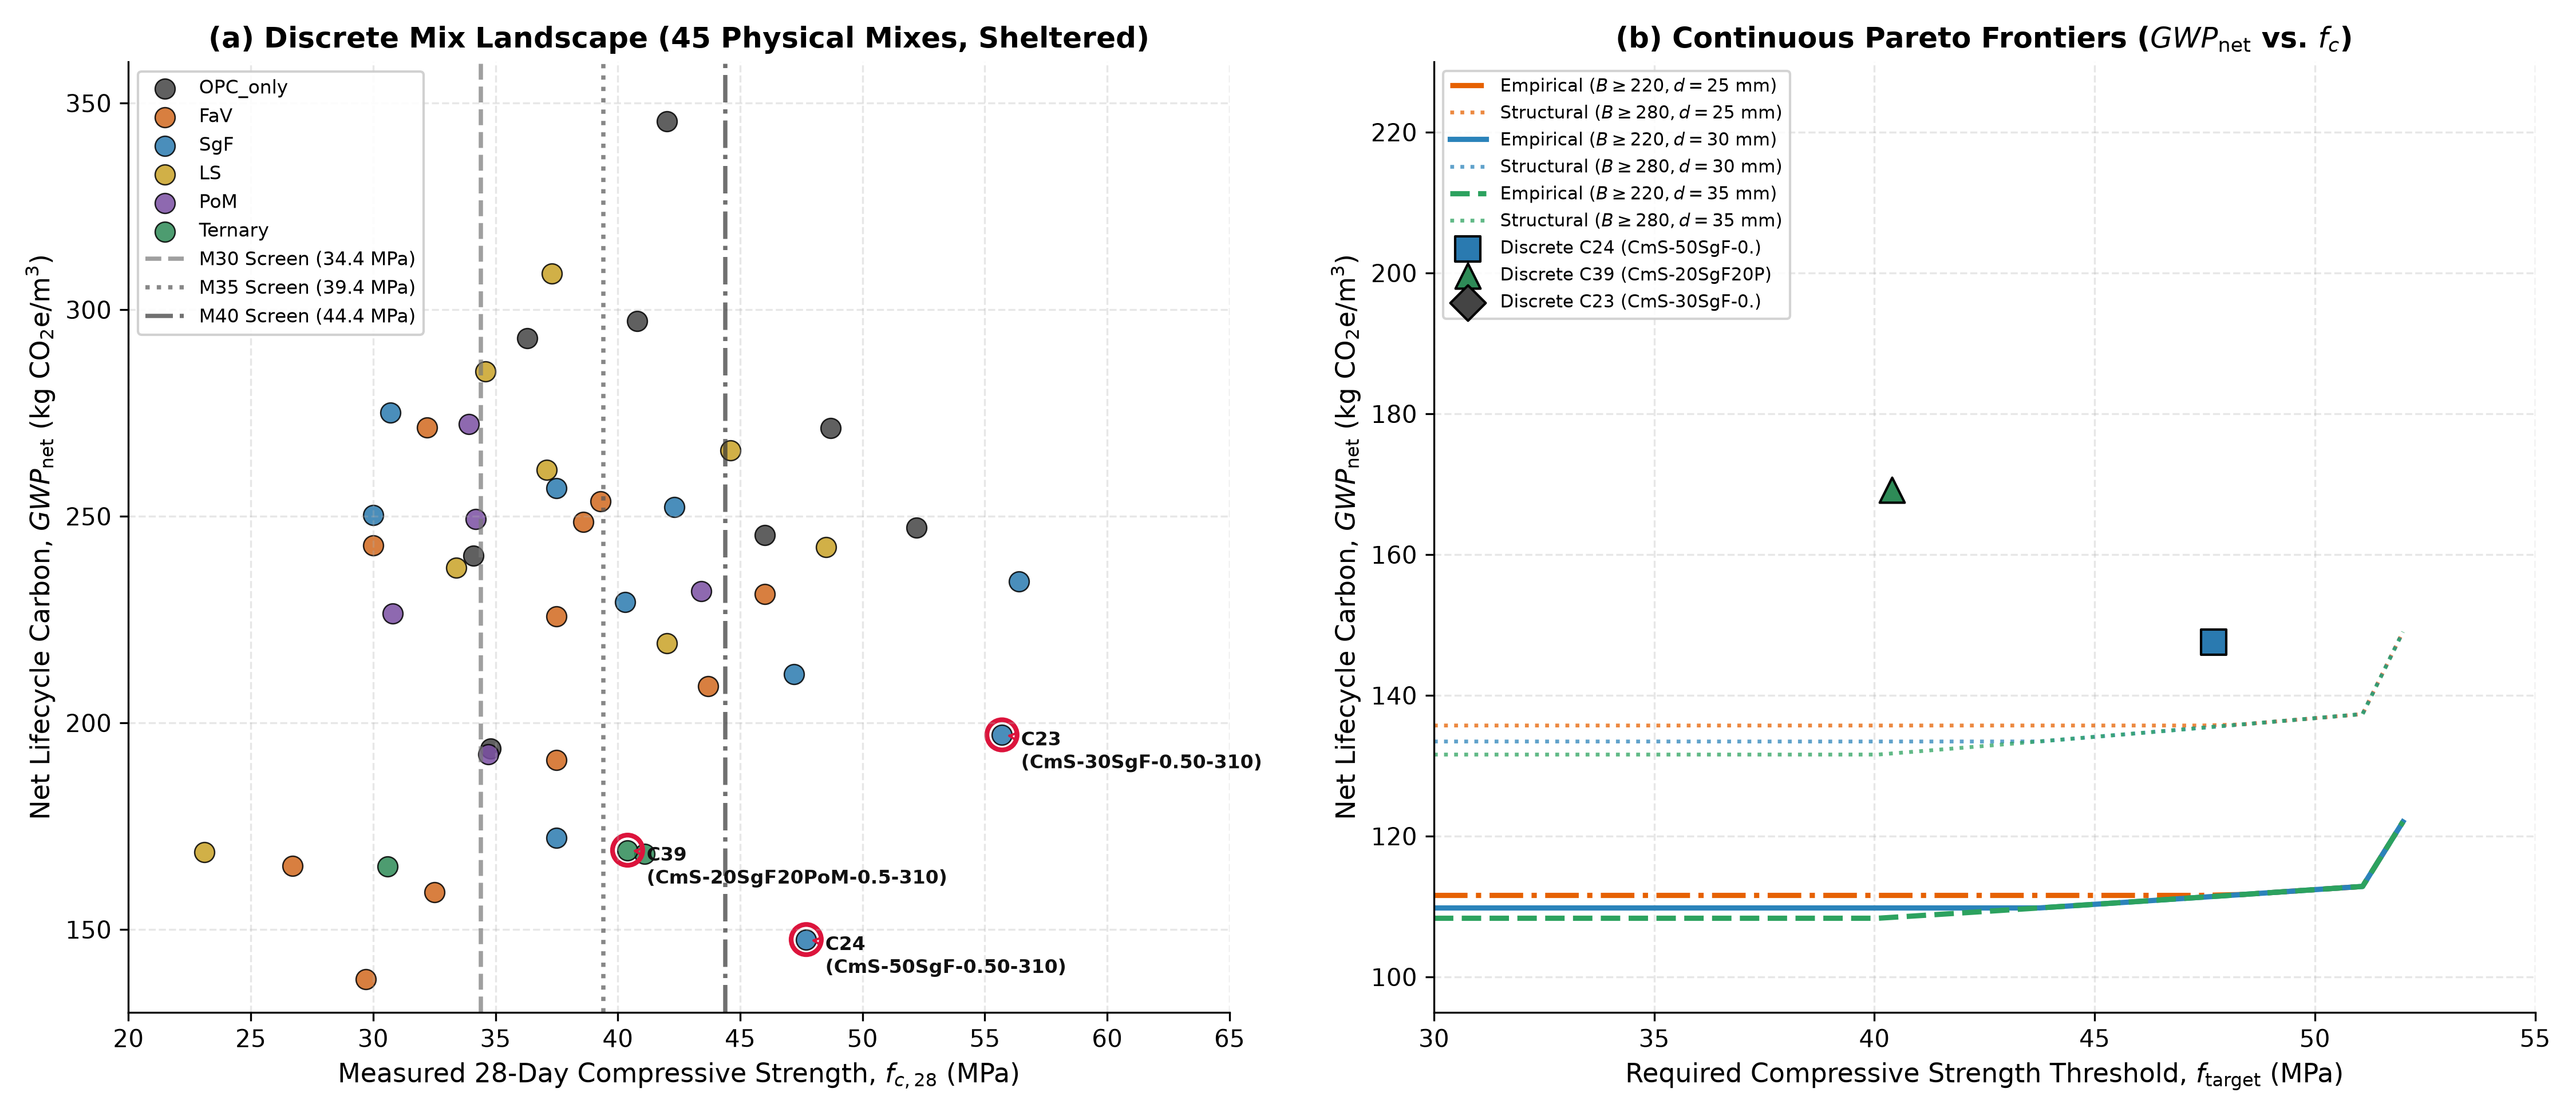

In [4]:
# Display Publication-Quality Figure 6
from IPython.display import Image, display
display(Image(filename='fig6_pareto_carbon_vs_strength.png'))


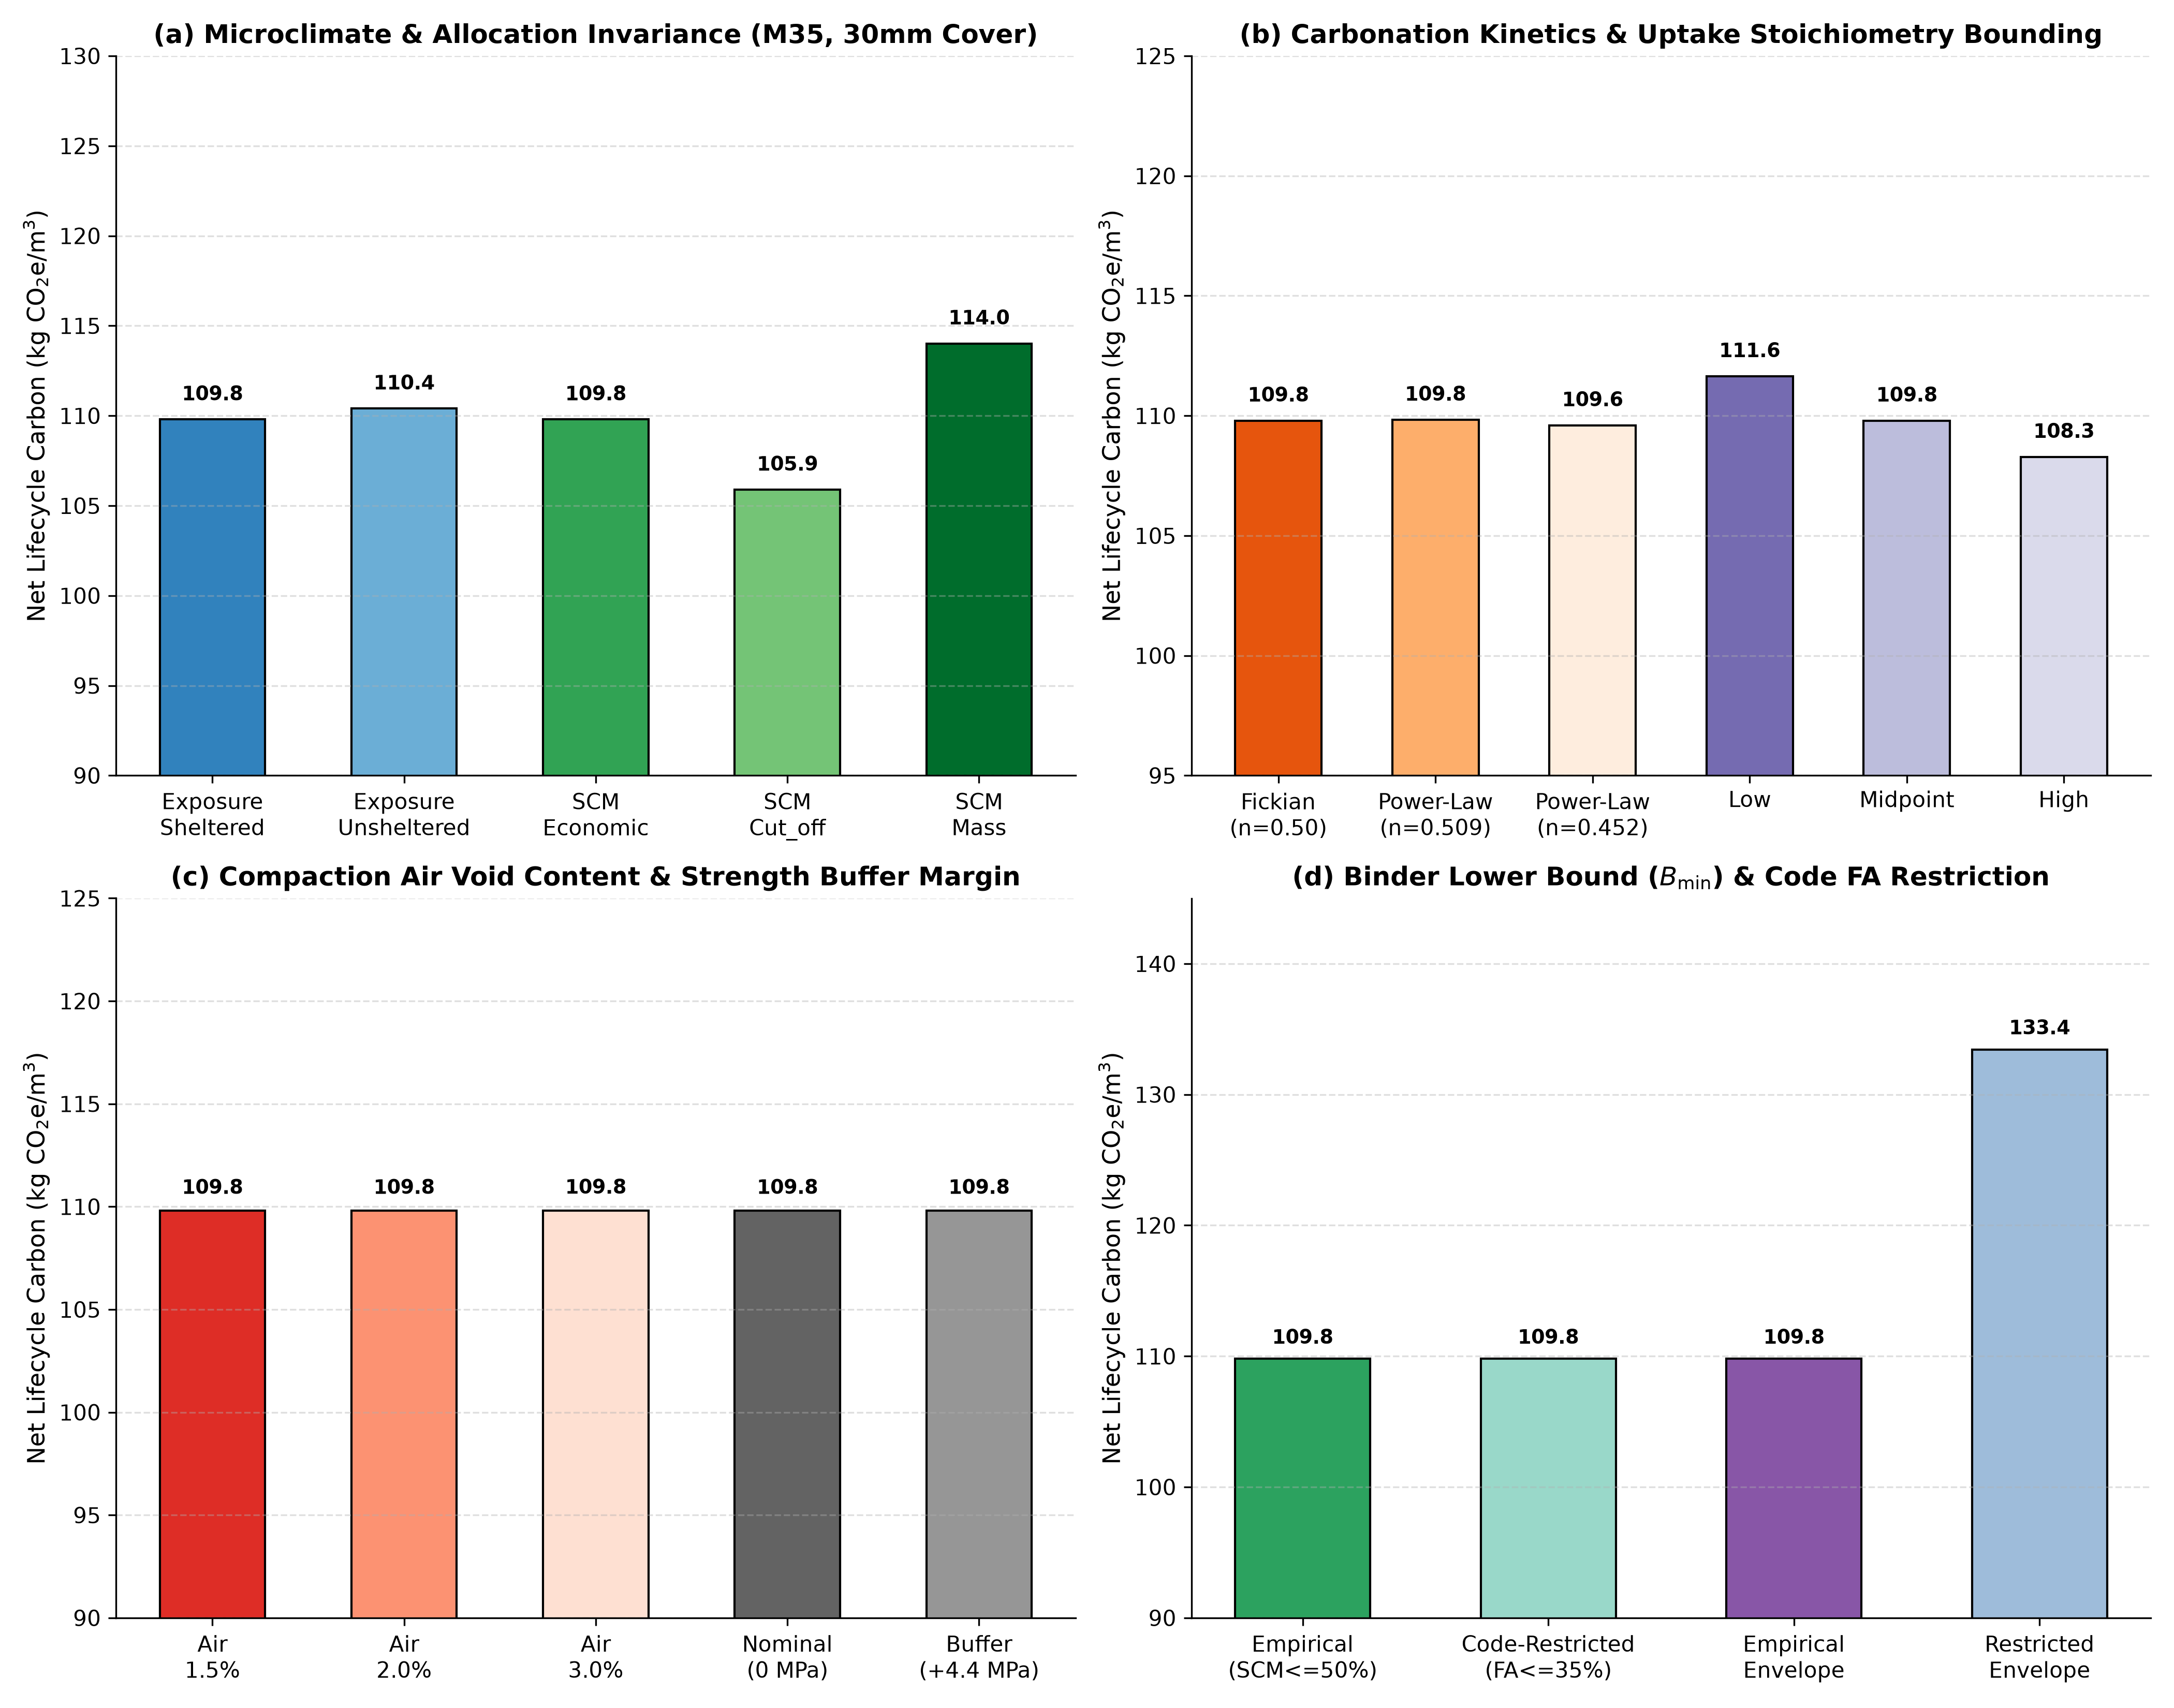

In [5]:
# Display Publication-Quality Figure 7
display(Image(filename='fig7_sensitivity_analysis.png'))
